# 5. Clustering: controlled baseline comparison

Compare K-Means across the three representations from Notebook 4. Do not refit scalers/PCA here, remove flagged customers, force eight clusters, or manually split customers by age.

This is a first model-comparison stage, not a claim that K-Means is optimal. Prototype-hierarchical and SOM benchmarks may be added after reviewing the baseline, if they address an observed limitation.

Selection combines within-space metrics, initialization/subsampling sensitivity, cluster sizes, and original-unit profiles. Silhouette and inertia are not a global leaderboard across feature spaces. Cluster IDs are arbitrary labels, not ordered customer categories.

Dependencies: numpy, pandas, matplotlib, scikit-learn, joblib. Run Notebook 4 first. Full-data fitting may take several minutes; silhouette is sampled to avoid repeated full pairwise calculations.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
feature_dir = project_root / "data" / "features"
cluster_dir = project_root / "models" / "clustering"
table_dir = project_root / "reports" / "tables" / "clustering"
figure_dir = project_root / "reports" / "figures" / "clustering"
for directory in [cluster_dir, table_dir, figure_dir]:
    directory.mkdir(parents=True, exist_ok=True)

from utils.clustering_functions import evaluate_kmeans, plot_kmeans_search
from utils.profiling_functions import build_cluster_profiles

## 1. Load prepared inputs and verify customer alignment

In [2]:
names = ["original_scaled", "log_scaled", "log_pca"]
representations = {
    name: pd.read_csv(feature_dir / f"{name}.csv", index_col="customer_id")
    for name in names
}
ids = representations[names[0]].index
population = pd.read_csv(feature_dir / "customer_population.csv")
expected_ids = population.loc[population["status"].eq("fitting"), "customer_id"]
assert ids.is_unique and ids.notna().all()
assert set(ids) == set(expected_ids)
for name, matrix in representations.items():
    assert matrix.index.equals(ids)
    assert np.isfinite(matrix.to_numpy()).all()
    print(name, matrix.shape)

profiles = pd.read_csv(feature_dir / "customer_profiles.csv", index_col="customer_id")
profiles = profiles.loc[ids].copy()
spend_columns = [c for c in profiles if c.startswith("spend_per_year_")]
assert len(spend_columns) == 10

original_scaled (33715, 11)
log_scaled (33715, 11)
log_pca (33715, 8)


## 2. Experiment settings
Start with k=2–10, three outer seeds, and ten initializations inside each fit. These values define a manageable first search, not a prior that the true number of segments lies in this range. Expand the range if evidence warrants it.

The same random customer sample is used for silhouette across runs. Small clusters may be underrepresented or absent in that sample; check the sample cluster count and full-data cluster sizes. Seed ARI compares assignments ignoring arbitrary label numbering; it is not accuracy against ground truth.

In [3]:
K_VALUES = list(range(2, 11))
SEEDS = [11, 42, 73]
N_INIT = 10
SILHOUETTE_SAMPLE = 2000

runs, summary, seed_stability, models, assignments, sample_ids = evaluate_kmeans(
    representations, K_VALUES, seeds=SEEDS, n_init=N_INIT,
    silhouette_sample=SILHOUETTE_SAMPLE,
)
display(summary.round(4))

,representation,k,silhouette_mean,silhouette_sd,inertia_mean,db_mean,min_cluster_pct,max_cluster_pct,clusters_found_min,any_iteration_limit,mean_seconds,seed_ari_mean,seed_ari_min,candidate_id
0,log_pca,2,0.2351,0.0007,248576.9233,1.5248,48.1685,51.8315,2,False,0.3917,0.9833,0.9750,log_pca__k2
1,log_pca,3,0.2501,0.0004,208031.6366,1.3492,13.0061,47.7265,3,False,0.4601,0.9913,0.9870,log_pca__k3
2,log_pca,4,0.2273,0.0001,177018.6979,1.3903,13.0001,46.8456,4,False,0.5188,0.9962,0.9944,log_pca__k4
3,log_pca,5,0.2234,0.0002,163229.5140,1.4798,11.2235,40.7118,5,False,0.6469,0.9966,0.9949,log_pca__k5
4,log_pca,6,0.2150,0.0001,150882.1715,1.5195,10.5354,32.1311,6,False,0.7382,0.9949,0.9932,log_pca__k6
5,log_pca,7,0.2035,0.0005,140724.9407,1.5024,7.9253,21.8894,7,False,0.7417,0.9825,0.9741,log_pca__k7
6,log_pca,8,0.1891,0.0006,135729.3538,1.5960,3.3665,21.0974,8,False,0.9915,0.7485,0.6252,log_pca__k8
7,log_pca,9,0.1883,0.0003,130990.3161,1.5632,3.2389,20.1542,9,False,1.2518,0.9680,0.9524,log_pca__k9
8,log_pca,10,0.1792,0.0048,126845.4620,1.6622,3.0046,18.7928,10,False,1.3985,0.8638,0.7961,log_pca__k10
9,log_scaled,2,0.2195,0.0003,275834.3221,1.6157,47.9786,52.0214,2,False,0.3857,0.9913,0.9871,log_scaled__k2


## 3. Within-representation diagnostics
Look for meaningful trade-offs rather than automatically maximizing silhouette. Small clusters are review signals, not automatically bad segments. Check whether an iteration limit was reached.

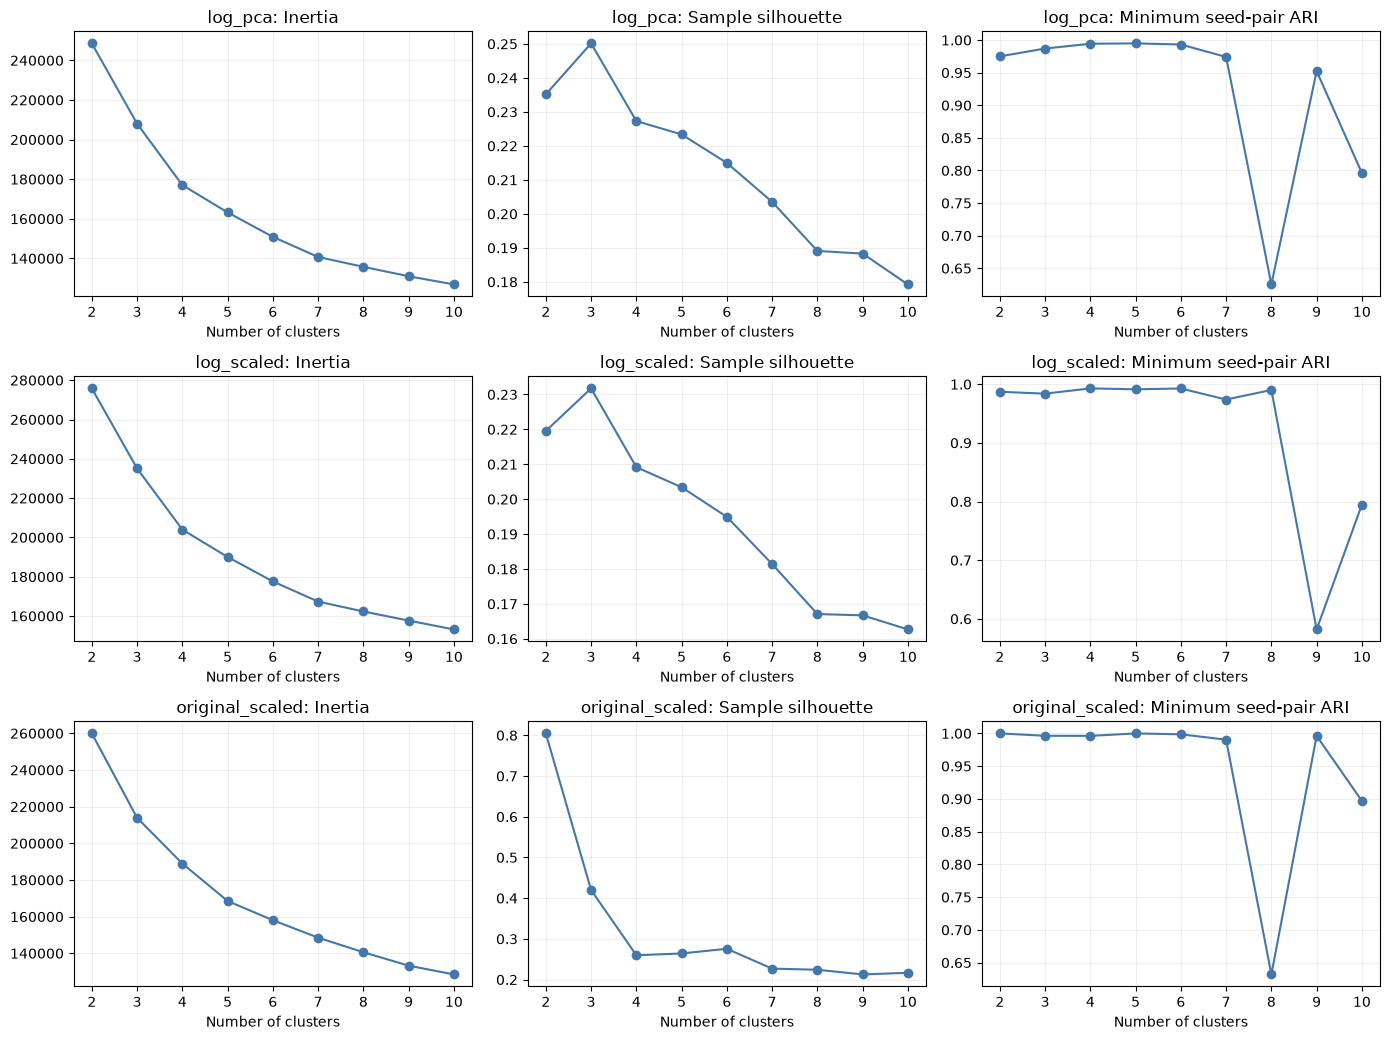

,representation,k,seed,inertia,silhouette_sample,sample_clusters_seen,davies_bouldin,clusters_found,min_cluster_count,min_cluster_pct,max_cluster_pct,iterations,iteration_limit_reached,seconds


min   mean
representation  k               
log_pca         2   0.975  0.983
                3   0.987  0.991
                4   0.994  0.996
                5   0.995  0.997
                6   0.993  0.995
                7   0.974  0.983
                8   0.625  0.748
                9   0.952  0.968
                10  0.796  0.864
log_scaled      2   0.987  0.991
                3   0.984  0.989
                4   0.993  0.994
                5   0.991  0.994
                6   0.993  0.995
                7   0.974  0.982
                8   0.990  0.993
                9   0.582  0.681
                10  0.795  0.858
original_scaled 2   1.000  1.000
                3   0.996  0.998
                4   0.996  0.997
                5   1.000  1.000
                6   0.999  0.999
                7   0.990  0.994
                8   0.632  0.755
                9   0.996  0.997
                10  0.897  0.930

In [4]:
fig = plot_kmeans_search(summary)
fig.savefig(figure_dir / "kmeans_search.png", dpi=160, bbox_inches="tight")
plt.show()

display(runs.loc[
    runs["iteration_limit_reached"] | runs["sample_clusters_seen"].lt(runs["k"])
])
display(seed_stability.groupby(["representation", "k"])["ari"].agg(["min", "mean"]).round(3))

## 4. Preliminary profiles for every candidate
Compute profiles in original spending units on the identical fitting population. Totals describe recorded annualized spend, not profit or verified customer lifetime value. Promotion-share differences are descriptive, not measured responsiveness to a campaign.

In [5]:
candidate_profiles = {}
for candidate_id, labels in assignments.items():
    candidate_profiles[candidate_id] = build_cluster_profiles(profiles, labels, spend_columns)

# One inspectable example only; not a selected winner.
EXAMPLE_CANDIDATE = "log_scaled__k6"
display(candidate_profiles[EXAMPLE_CANDIDATE]["sizes"].round(2))
display(candidate_profiles[EXAMPLE_CANDIDATE]["spending_medians"].round(2))
display(candidate_profiles[EXAMPLE_CANDIDATE]["overview"].round(2))

,customers,customer_pct,share_of_recorded_annual_spending_pct
cluster,,,
0,10876,32.26,26.78
1,3521,10.44,13.17
2,5314,15.76,4.99
3,5137,15.24,11.97
4,4496,13.34,37.50
5,4371,12.96,5.58


,spend_per_year_groceries,spend_per_year_electronics,spend_per_year_vegetables,spend_per_year_nonalcohol_drinks,spend_per_year_alcohol_drinks,spend_per_year_meat,spend_per_year_fish,spend_per_year_hygiene,spend_per_year_petfood,spend_per_year_videogames
cluster,,,,,,,,,,
0,1920.15,317.46,49.00,45.76,93.72,97.70,92.00,68.50,26.29,30.54
1,2574.88,1014.91,16.18,63.15,130.50,107.75,107.56,22.00,36.57,121.50
2,859.10,33.15,27.10,13.71,15.00,63.36,28.11,32.64,23.50,11.80
3,2051.27,152.93,28.45,39.10,46.66,90.14,66.00,80.33,33.58,24.18
4,5968.40,916.41,134.50,116.15,224.17,228.53,230.58,159.06,71.75,96.42
5,939.35,181.93,184.82,36.76,36.80,4.67,6.62,65.27,22.57,18.56


total_annual_spending          pct_prod_in_promotion           age  \
                         mean   median                  mean median   mean   
cluster                                                                      
0                     3286.26  2818.25                  0.18   0.16  56.77   
1                     4992.96  4274.80                  0.26   0.24  55.13   
2                     1254.57  1150.05                  0.48   0.49  55.04   
3                     3110.82  2759.00                  0.64   0.63  52.46   
4                    11132.11  8595.85                  0.25   0.19  48.06   
5                     1704.99  1511.00                  0.10   0.10  57.44   

               child_home        customer_lifetime         \
        median       mean median              mean median   
cluster                                                     
0         57.0       2.96    2.0             12.75   13.0   
1         55.0       0.84    1.0              8.49    8.0   
2         54.0       1.74    2.0             12.33   12.0   
3         52.0       1.80    2.0              9.76    9.0   
4         46.0       2.31    2.0              5.14    5.0   
5         57.0       1.28    1.0             10.78   11.0   

        distinct_stores_visited        lifetime_total_distinct_products         
                           mean median                             mean median  
cluster                                                                         
0                          2.86    3.0                           219.85  210.0  
1                          1.60    1.0                           123.53  109.0  
2                          3.57    4.0                            70.36   55.0  
3                          3.32    3.0                           155.96  116.0  
4                          2.50    2.0                           208.01  189.0  
5                          3.14    3.0                            81.47   81.0

## 5. Cross-representation assignment comparison
For the same k, ARI tells us whether customers are grouped similarly after changing representation. Agreement is not proof of quality; disagreement identifies where original-unit profiles need review.

In [6]:
from itertools import combinations
from sklearn.metrics import adjusted_rand_score
cross_rows = []
for k in K_VALUES:
    for a, b in combinations(names, 2):
        cross_rows.append({"k": k, "representation_a": a, "representation_b": b,
            "ari": adjusted_rand_score(assignments[f"{a}__k{k}"], assignments[f"{b}__k{k}"])})
cross_comparison = pd.DataFrame(cross_rows)
display(cross_comparison.round(3))

,k,representation_a,representation_b,ari
0,2,original_scaled,log_scaled,-0.001
1,2,original_scaled,log_pca,-0.001
2,2,log_scaled,log_pca,0.997
3,3,original_scaled,log_scaled,0.021
4,3,original_scaled,log_pca,0.020
5,3,log_scaled,log_pca,0.995
6,4,original_scaled,log_scaled,0.260
7,4,original_scaled,log_pca,0.264
8,4,log_scaled,log_pca,0.978
9,5,original_scaled,log_scaled,0.230


## 6. Export candidates for Notebook 6
One minimum-inertia seed run is retained per representation/k, never across different representations or different k. These are candidate artifacts, not final production models.

Only load joblib files you trust. Notebook 4 records preparation package versions; this notebook also records its experiment settings.

In [7]:
import platform
import importlib.metadata
runs.to_csv(table_dir / "kmeans_runs.csv", index=False)
summary.to_csv(table_dir / "kmeans_summary.csv", index=False)
seed_stability.to_csv(table_dir / "seed_stability.csv", index=False)
cross_comparison.to_csv(table_dir / "cross_representation_ari.csv", index=False)
pd.Series(sample_ids, name="customer_id").to_csv(table_dir / "silhouette_sample_ids.csv", index=False)

label_table = pd.DataFrame(assignments, index=ids)
label_table.to_csv(cluster_dir / "candidate_assignments.csv", index_label="customer_id")
joblib.dump(models, cluster_dir / "candidate_models.joblib")
for candidate_id, tables in candidate_profiles.items():
    destination = table_dir / "candidates" / candidate_id
    destination.mkdir(parents=True, exist_ok=True)
    for name, table in tables.items():
        table.to_csv(destination / f"{name}.csv")

settings = {
    "algorithm": "KMeans", "k_values": K_VALUES, "outer_seeds": SEEDS,
    "n_init": N_INIT, "max_iter": 300, "silhouette_sample": len(sample_ids),
    "sample_seed": 42, "retained_run_rule": "Minimum inertia within representation and k",
    "fitting_customers": len(ids), "final_selection": None,
    "python": platform.python_version(),
    "versions": {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scikit-learn", "joblib"]},
}
(cluster_dir / "experiment_settings.json").write_text(json.dumps(settings, indent=2))
print("Candidate search exported. Review profiles and stability in Notebook 6 before final selection.")

Candidate search exported. Review profiles and stability in Notebook 6 before final selection.


## Baseline Findings and Handoff

The original-scaled two-cluster solution achieved a high silhouette score
but placed approximately 97.84% of customers in one cluster. It is retained
as a diagnostic of extreme-spending separation rather than selected as
the overall segmentation.

Within both log-based representations, three clusters achieved the
highest silhouette among the tested settings. Five- and six-cluster
log-scaled solutions also showed high agreement across tested seeds.

The six-cluster log-scaled solution revealed preliminary distinctions
in promotion purchasing and category spending beyond overall spending
intensity.

At six clusters, log-scaled and log-PCA assignments were very similar
(ARI = 0.973). Both remain available for profile comparison.

Notebook 6 will compare the three-, five-, and six-cluster log-scaled
solutions and the six-cluster log-PCA solution. No final model has
been selected.